In [1]:
%load_ext autoreload
%autoreload 2

In [150]:
import copy
import random
import math
import numpy as np
import pandas as pd

# Your project imports
from tsn_scheduling_problem import TSNScheduling
from schedule import Schedule, Slot

# Benchmark utilities you already have
from benchmark_utils import (
    build_network_generator_from_usecase,
    generate_one_arrival_stream,
    build_usecase_stream_from_request,
)

# Optional: cleaner printing
np.set_printoptions(suppress=True, linewidth=140)

print("Imports loaded.")

Imports loaded.


In [192]:
CONFIG_PATH = "uc_config.cfg"
INSTANCE_PATH = "banana3.json"   # change if you want another instance

problem = TSNScheduling(CONFIG_PATH)
instance = problem.import_scheduling_usecase(INSTANCE_PATH)

# Keep problem aligned with this instance
problem.usecase = instance
problem.build_metadata()

print("Loaded instance:", INSTANCE_PATH)
print("Number of streams in usecase:", len(instance.streams))
print("Number of scheduled slots:", len(instance.schedule))

active_stream_ids = sorted({
    int(slot.stream_id)
    for slot in instance.schedule
    if slot.stream_id is not None
})

print("Active scheduled streams:", len(active_stream_ids))
print("Active stream IDs:", active_stream_ids)
print("Cycle ns:", instance.schedule.cycle_ns)

Loaded instance: banana3.json
Number of streams in usecase: 62
Number of scheduled slots: 18
Active scheduled streams: 5
Active stream IDs: [4, 14, 23, 24, 38]
Cycle ns: 300000


In [152]:
from evaluator import TSNConstraintEvaluator, ScheduleEncodingType

def check_schedule_validity(instance, problem, label="schedule"):
    """
    Check whether the current instance.schedule has evaluator violations.
    """
    problem.usecase = instance
    problem.build_metadata()

    evaluator = TSNConstraintEvaluator(
        problem,
        check_routing=False,
        check_task_placement=False,
        scheduling_type=ScheduleEncodingType.START_TIME,
    )

    compact = instance.schedule.to_compact_encoding(
        problem.n_ports,
        problem.n_streams,
    )

    violations = evaluator.per_stream_all_violations(compact)

    breakdown = {
        "seq": int(violations[0].sum()) if violations.shape[0] > 0 else 0,
        "fifo": int(violations[1].sum()) if violations.shape[0] > 1 else 0,
        "macrocycle": int(violations[2].sum()) if violations.shape[0] > 2 else 0,
        "talker_offset": int(violations[3].sum()) if violations.shape[0] > 3 else 0,
        "latency": int(violations[4].sum()) if violations.shape[0] > 4 else 0,
        "total": int(violations.sum()),
    }

    print(f"[{label}] violation breakdown:", breakdown)
    return breakdown

validity = check_schedule_validity(instance, problem, label="initial")

[initial] violation breakdown: {'seq': 0, 'fifo': 0, 'macrocycle': 0, 'talker_offset': 0, 'latency': 0, 'total': 0}


In [184]:
DRL_MODEL_PATH_V27 = "runs/run_27_env_v2_100/best_model"

DRL_TRAIN_CONFIG_V27 = {
    "max_candidates": 5,
    "max_hops": 6,
    "max_steps": 500,

    "init_from_usecase_schedule": True,
    "include_current_offset_candidate": True,

    "per_hop_candidate_limit": 5,
    "beam_width": 30,

    "defrag_cycle_penalty": 0.6,
    "reallocation_penalty": 0.05,
    "invalid_penalty": 10.0,

    "useless_gap_threshold_bytes": 1024,
    "expected_incoming_bytes": 1024,

    "top_k_oldest_random": 10,
}

In [154]:
from stable_baselines3 import DQN
from env import TSNCandidatePathEnv


def make_drl_eval_env(
    instance,
    problem,
    seed=42,
    lambda_arrival=0.75,
    decision_points_per_episode=300,
    cfg=None,
):
    cfg = cfg or DRL_TRAIN_CONFIG

    prob = copy.deepcopy(problem)
    inst = copy.deepcopy(instance)
    prob.usecase = inst
    prob.build_metadata()

    env = TSNCandidatePathEnv(
        problem=prob,
        usecase=inst,
        useless_gap_threshold_bytes=cfg["useless_gap_threshold_bytes"],
        expected_incoming_bytes=cfg["expected_incoming_bytes"],
        invalid_penalty=cfg["invalid_penalty"],
        max_candidates=cfg["max_candidates"],
        max_steps=cfg["max_steps"],
        max_hops=cfg["max_hops"],
        init_from_usecase_schedule=cfg["init_from_usecase_schedule"],
        include_current_offset_candidate=cfg["include_current_offset_candidate"],
        per_hop_candidate_limit=cfg["per_hop_candidate_limit"],
        beam_width=cfg["beam_width"],
        defrag_cycle_penalty=cfg["defrag_cycle_penalty"],
        reallocation_penalty=cfg["reallocation_penalty"],
        lambda_arrival=lambda_arrival,
        mu_departure=1.0,  # not very important for shared-trace mode, but keep stable
        dt=1.0,
        decision_points_per_episode=decision_points_per_episode,
        top_k_oldest_random=cfg["top_k_oldest_random"],
        seed=seed,
    )

    return env


def check_drl_model_env_compatibility(model_path, instance, problem, cfg=None):
    env = make_drl_eval_env(
        instance=instance,
        problem=problem,
        seed=42,
        lambda_arrival=0.75,
        decision_points_per_episode=300,
        cfg=cfg,
    )

    model = DQN.load(model_path)

    print("Model observation space:")
    print(model.observation_space)

    print("\nEval env observation space:")
    print(env.observation_space)

    print("\nModel action space:")
    print(model.action_space)

    print("\nEval env action space:")
    print(env.action_space)

    print("\nObservation spaces equal:", model.observation_space == env.observation_space)
    print("Action spaces equal:", model.action_space == env.action_space)

    return model, env

model_check, env_check = check_drl_model_env_compatibility(
    model_path=DRL_MODEL_PATH,
    instance=instance,
    problem=problem,
    cfg=DRL_TRAIN_CONFIG,
)

Model observation space:
Dict('base_features': Box(-1.0, 1.0, (7,), float32), 'candidate_features': Box(-1.0, 1.0, (5, 4), float32), 'candidate_mask': Box(0, 1, (6,), int8), 'candidate_offsets': Box(-1.0, 1.0, (5, 6), float32), 'current_offsets': Box(-1.0, 1.0, (6,), float32))

Eval env observation space:
Dict('base_features': Box(-1.0, 1.0, (7,), float32), 'candidate_features': Box(-1.0, 1.0, (5, 4), float32), 'candidate_mask': Box(0, 1, (6,), int8), 'candidate_offsets': Box(-1.0, 1.0, (5, 6), float32), 'current_offsets': Box(-1.0, 1.0, (6,), float32))

Model action space:
Discrete(6)

Eval env action space:
Discrete(6)

Observation spaces equal: True
Action spaces equal: True


In [155]:
def generate_long_decision_trace(
    instance,
    max_steps=10000,
    lambda_arrival=1.0,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
):
    """
    Generate a long shared trace for decision-point experiments.

    Each step contains:
      - n_dep = 1 departure opportunity
      - arrivals sampled from Poisson(lambda_arrival * dt)

    The runner decides when to stop based on actual departures.
    """
    rng_np = np.random.default_rng(seed)

    ng = build_network_generator_from_usecase(copy.deepcopy(instance))

    trace = []

    for _ in range(int(max_steps)):
        n_arr = int(rng_np.poisson(lambda_arrival * dt))

        arrivals = []
        for _ in range(n_arr):
            raw_stream = generate_one_arrival_stream(
                ng,
                ed_ed_settings=ed_ed_settings,
            )
            arrivals.append(raw_stream)

        trace.append({
            "n_dep": 1,
            "arrivals": arrivals,
        })

    return trace


# quick smoke test
trace_test = generate_long_decision_trace(
    instance=instance,
    max_steps=5,
    lambda_arrival=1.0,
    seed=42,
)

print("Trace length:", len(trace_test))
for i, step in enumerate(trace_test, start=1):
    print(i, "n_dep:", step["n_dep"], "n_arrivals:", len(step["arrivals"]))

Trace length: 5
1 n_dep: 1 n_arrivals: 1
2 n_dep: 1 n_arrivals: 2
3 n_dep: 1 n_arrivals: 3
4 n_dep: 1 n_arrivals: 1
5 n_dep: 1 n_arrivals: 3


In [156]:
def get_active_stream_ids(schedule):
    return sorted({
        int(slot.stream_id)
        for slot in schedule
        if slot.stream_id is not None
    })


def build_port_intervals(schedule):
    relevant_ports = sorted({
        int(slot.port_id)
        for slot in schedule
        if slot.port_id is not None
    })

    return {
        pid: schedule._occupied_intervals_on_port(pid, schedule.cycle_ns)
        for pid in relevant_ports
    }


def init_stream_arrival_times(schedule):
    """
    Initial streams are considered already present at time 0.
    """
    return {
        int(sid): 0.0
        for sid in get_active_stream_ids(schedule)
    }


def summarize_decisions(decisions):
    """
    decisions maps arrival_id -> one of:
      accept, scheduler_reject, raw_none, build_none
    """
    counts = {
        "accept": 0,
        "scheduler_reject": 0,
        "raw_none": 0,
        "build_none": 0,
    }

    for v in decisions.values():
        if v in counts:
            counts[v] += 1
        else:
            counts[v] = counts.get(v, 0) + 1

    return counts


def batch_left_compact_streams_preserve_id(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Clean batch left-compaction with preserved stream IDs.

    Steps:
      1. Backup full schedule and stream metadata.
      2. Remove all selected stream slots as a batch.
      3. Reinsert each selected stream using preserve-ID first-fit-fast.
      4. If any stream fails, rollback everything.
      5. Return moved stream IDs.
    """
    import copy

    stream_ids = [int(sid) for sid in stream_ids]

    if not stream_ids:
        return {
            "success": True,
            "moved_stream_ids": [],
            "failed_stream_ids": [],
        }

    # Full backup for rollback
    old_schedule_slots = copy.deepcopy(list(schedule))
    old_streams = copy.deepcopy(usecase.streams)

    old_offsets = {
        sid: sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )
        for sid in stream_ids
    }

    # Check all streams exist and are scheduled
    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

        if not old_offsets.get(sid):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

    selected_set = set(stream_ids)

    # Remove all selected stream slots together
    schedule[:] = [
        slot for slot in schedule
        if slot.stream_id is None or int(slot.stream_id) not in selected_set
    ]
    schedule.sort()

    # Rebuild intervals after batch removal
    if port_intervals is not None:
        port_intervals.clear()
        port_intervals.update(build_port_intervals(schedule))

    problem.usecase = usecase
    problem.build_metadata()

    failed_stream_ids = []

    for sid in stream_ids:
        result = schedule.place_existing_stream_first_fit_fast(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            failed_stream_ids.append(sid)
            break

    if failed_stream_ids:
        # Full rollback
        schedule[:] = old_schedule_slots
        schedule.sort()

        usecase.streams = old_streams

        problem.usecase = usecase
        problem.build_metadata()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        usecase.removeSchedule()
        _, port_id_to_name = usecase.port_name_id_mapping
        usecase.schedule = schedule
        schedule.update_graph(usecase.graph, port_id_to_name)

        return {
            "success": False,
            "moved_stream_ids": [],
            "failed_stream_ids": failed_stream_ids,
        }

    # Count real moved streams
    moved_stream_ids = []

    for sid in stream_ids:
        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if old_offsets.get(sid, []) != new_offsets:
            moved_stream_ids.append(sid)

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": [],
    }


def batch_right_compact_streams_preserve_id(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=5,
    beam_width=3,
):
    """
    Clean batch right-compaction with preserved stream IDs.

    Steps:
      1. Backup full schedule and stream metadata.
      2. Remove all selected stream slots as a batch.
      3. Reinsert each selected stream using preserve-ID right-fit.
      4. If any stream fails, rollback everything.
      5. Return moved stream IDs.
    """
    import copy

    stream_ids = [int(sid) for sid in stream_ids]

    if not stream_ids:
        return {
            "success": True,
            "moved_stream_ids": [],
            "failed_stream_ids": [],
        }

    old_schedule_slots = copy.deepcopy(list(schedule))
    old_streams = copy.deepcopy(usecase.streams)

    old_offsets = {
        sid: sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )
        for sid in stream_ids
    }

    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

        if not old_offsets.get(sid):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

    selected_set = set(stream_ids)

    schedule[:] = [
        slot for slot in schedule
        if slot.stream_id is None or int(slot.stream_id) not in selected_set
    ]
    schedule.sort()

    if port_intervals is not None:
        port_intervals.clear()
        port_intervals.update(build_port_intervals(schedule))

    problem.usecase = usecase
    problem.build_metadata()

    failed_stream_ids = []

    for sid in stream_ids:
        result = schedule.place_existing_stream_right_fit_backward(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            failed_stream_ids.append(sid)
            break

    if failed_stream_ids:
        schedule[:] = old_schedule_slots
        schedule.sort()

        usecase.streams = old_streams

        problem.usecase = usecase
        problem.build_metadata()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        usecase.removeSchedule()
        _, port_id_to_name = usecase.port_name_id_mapping
        usecase.schedule = schedule
        schedule.update_graph(usecase.graph, port_id_to_name)

        return {
            "success": False,
            "moved_stream_ids": [],
            "failed_stream_ids": failed_stream_ids,
        }

    moved_stream_ids = []

    for sid in stream_ids:
        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if old_offsets.get(sid, []) != new_offsets:
            moved_stream_ids.append(sid)

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": [],
    }


def oldest_first_left_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    OF-LC(p,n): Oldest-First Left-Compaction with preserved stream IDs.

    Every p departures:
      1. Select n oldest active streams.
      2. Remove them as a batch.
      3. Reinsert them from the left using preserve-ID first-fit-fast.
      4. Roll back if the batch cannot be fully reinserted.
    """
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = batch_left_compact_streams_preserve_id(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", []) if result.get("success") else []

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": result.get("success", False),
        "failed_stream_ids": result.get("failed_stream_ids", []),
    }


def oldest_first_right_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=5,
    beam_width=3,
):
    """
    OF-RC(p,n): Oldest-First Right-Compaction with preserved stream IDs.

    Every p departures:
      1. Select n oldest active streams.
      2. Remove them as a batch.
      3. Reinsert them from the right using backward right-fit.
      4. Roll back if the batch cannot be fully reinserted.
    """
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = batch_right_compact_streams_preserve_id(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", []) if result.get("success") else []

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": result.get("success", False),
        "failed_stream_ids": result.get("failed_stream_ids", []),
    }


def place_new_stream_with_existing_fast(
    schedule,
    stream,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Place a new arrival stream using the preserve-ID existing-stream placement.

    This replaces schedule.place_stream_first_fit_fast(...).
    """
    import copy

    stream_id = len(usecase.streams)

    # Append new stream definition first, so metadata/evaluator knows it exists
    usecase.streams.append(copy.deepcopy(stream))

    result = schedule.place_existing_stream_first_fit_fast(
        stream_id=stream_id,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    if result.get("accepted"):
        return result

    # If rejected, remove the appended stream definition again
    usecase.streams.pop()
    problem.usecase = usecase
    problem.build_metadata()

    return {
        "accepted": [],
        "rejected": [stream_id],
    }


print("Helper functions loaded.")

Helper functions loaded.


In [157]:
def run_no_defrag_decision_trace(
    instance,
    problem,
    trace,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Run No-Defrag on a shared long trace.

    Episode stops when actual departures reach decision_points_per_episode.
    Arrivals are whatever occurred during those trace steps.
    """
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

        # -------------------------
        # Arrivals after departure
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "decisions": decisions,
    }


In [158]:
def run_of_lc_preserve_id_decision_trace(
    instance,
    problem,
    trace,
    p=20,
    n=5,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    successful_defrag_cycles = 0
    failed_defrag_cycles = 0
    actual_reallocations = 0

    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            # Trigger OF-LC every p actual departures
            while (
                p > 0
                and n > 0
                and next_defrag_trigger is not None
                and total_departures >= next_defrag_trigger
            ):
                defrag_result = oldest_first_left_compact_defrag_preserve_id(
                    schedule=sched,
                    usecase=inst,
                    problem=prob,
                    p=1,
                    n=n,
                    departure_counter=1,
                    queue_id=5,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                    max_candidates_per_hop=max_candidates_per_hop,
                    beam_width=beam_width,
                )

                if defrag_result.get("triggered", False):
                    actual_defrag_cycles += 1

                    if defrag_result.get("success", False):
                        successful_defrag_cycles += 1
                        actual_reallocations += int(defrag_result.get("replaced_count", 0))
                    else:
                        failed_defrag_cycles += 1

                next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(successful_defrag_cycles),
        "failed_defrag_cycles": int(failed_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,
    }

In [159]:
def run_of_rc_preserve_id_decision_trace(
    instance,
    problem,
    trace,
    p=8,
    n=10,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=5,
    beam_width=3,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    successful_defrag_cycles = 0
    failed_defrag_cycles = 0
    actual_reallocations = 0

    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            while (
                p > 0
                and n > 0
                and next_defrag_trigger is not None
                and total_departures >= next_defrag_trigger
            ):
                defrag_result = oldest_first_right_compact_defrag_preserve_id(
                    schedule=sched,
                    usecase=inst,
                    problem=prob,
                    p=1,
                    n=n,
                    departure_counter=1,
                    queue_id=5,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                    max_candidates_per_hop=max_candidates_per_hop,
                    beam_width=beam_width,
                )

                if defrag_result.get("triggered", False):
                    actual_defrag_cycles += 1

                    if defrag_result.get("success", False):
                        successful_defrag_cycles += 1
                        actual_reallocations += int(defrag_result.get("replaced_count", 0))
                    else:
                        failed_defrag_cycles += 1

                next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=2,
                beam_width=1,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(successful_defrag_cycles),
        "failed_defrag_cycles": int(failed_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,
    }

In [160]:
def run_of_ff_decision_trace(
    instance,
    problem,
    trace,
    p=8,
    n=10,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Run OF-FF on a shared long trace.

    Episode stops when actual departures reach decision_points_per_episode.
    OF-FF triggers every p actual departures.
    """
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    actual_reallocations = 0
    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            # Trigger OF-FF every p actual departures.
            while (
                p > 0
                and n > 0
                and next_defrag_trigger is not None
                and total_departures >= next_defrag_trigger
            ):
                defrag_result = sched.oldest_first_first_fit_defrag(
                    usecase=inst,
                    problem=prob,
                    p=1,                    # force trigger
                    n=n,
                    departure_counter=1,     # force trigger
                    queue_id=5,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )

                if defrag_result.get("triggered", False):
                    actual_defrag_cycles += 1
                    actual_reallocations += int(defrag_result.get("replaced_count", 0))

                next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,
    }

In [188]:
from stable_baselines3 import DQN
from env import TSNCandidatePathEnv
import torch

def run_drl_decision_trace(
    instance,
    problem,
    trace,
    model_path,
    decision_points_per_episode=300,
    seed=42,

    # Arrival scheduler params
    max_candidates_per_hop=2,
    beam_width=1,

    # DRL/env params
    drl_cfg=None,
    deterministic=True,
    max_actions_per_decision=100,
    debug=False,
    debug_max_decisions=3,
):
    drl_cfg = drl_cfg or DRL_TRAIN_CONFIG

    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    model = DQN.load(model_path)

    env = TSNCandidatePathEnv(
        problem=copy.deepcopy(prob),
        usecase=copy.deepcopy(inst),
        useless_gap_threshold_bytes=drl_cfg["useless_gap_threshold_bytes"],
        expected_incoming_bytes=drl_cfg["expected_incoming_bytes"],
        invalid_penalty=drl_cfg["invalid_penalty"],
        max_candidates=drl_cfg["max_candidates"],
        max_steps=drl_cfg["max_steps"],
        max_hops=drl_cfg["max_hops"],
        init_from_usecase_schedule=drl_cfg["init_from_usecase_schedule"],
        include_current_offset_candidate=drl_cfg["include_current_offset_candidate"],
        per_hop_candidate_limit=drl_cfg["per_hop_candidate_limit"],
        beam_width=drl_cfg["beam_width"],
        defrag_cycle_penalty=drl_cfg["defrag_cycle_penalty"],
        reallocation_penalty=drl_cfg["reallocation_penalty"],
        lambda_arrival=0.0,
        mu_departure=0.0,
        dt=1.0,
        decision_points_per_episode=decision_points_per_episode,
        top_k_oldest_random=drl_cfg["top_k_oldest_random"],
        seed=seed,
    )

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    actual_reallocations = 0
    invalid_moves = 0

    decisions = {}

    debug_decisions_seen = 0

    def sync_env_from_current_schedule():
        """
        Sync DRL env with the externally controlled benchmark state.
        """
        env.usecase = inst
        env.problem = prob
        env.problem.usecase = inst
        env.problem.build_metadata()
        env._rebuild_runtime_metadata()

        env._load_state_from_schedule(sched)
        env.usecase.schedule = sched
        env.port_intervals = build_port_intervals(sched)

        env.stream_arrival_times = dict(stream_arrival_times)
        env.current_time = float(step_count)
        env.in_defrag_cycle = False
        env.decision_active = False
        env.current_candidates = []

    def run_one_drl_decision():
        nonlocal actual_defrag_cycles
        nonlocal actual_reallocations
        nonlocal invalid_moves
        nonlocal debug_decisions_seen
        
        moved_this_decision = False

        sync_env_from_current_schedule()
        #diag_df = diagnose_drl_candidate_generation(env, n_decisions=1)
        #display(diag_df[["stream_id", "path_len", "candidate_count", "current_offsets", "candidate_offsets"]])

        active = env._active_stream_ids()
        if not active:
            return

        env.decision_stream_order = env._ordered_streams_by_age()
        env.decision_pointer = 0

        if not env.decision_stream_order:
            return

        env.focus.stream_id = int(env.decision_stream_order[0])
        env.current_candidates = env._candidate_list_for_stream(
            int(env.focus.stream_id)
        )
        env.decision_active = True
        env.in_defrag_cycle = False

        if debug and debug_decisions_seen < debug_max_decisions:
            print("\n[DRL decision]")
            print("Active streams:", len(active))
            print("Decision order:", env.decision_stream_order[:10])

        for action_step in range(max_actions_per_decision):
            obs = env._get_obs()
            action, _ = model.predict(obs, deterministic=deterministic)
            if debug and debug_decisions_seen < debug_max_decisions:
                obs_tensor, _ = model.policy.obs_to_tensor(obs)

                with torch.no_grad():
                    q_values = model.q_net(obs_tensor)
                    q_values = q_values.cpu().numpy().flatten()

                valid_mask = obs["candidate_mask"].astype(bool)

                print("  Q-values:")
                for a_idx, q in enumerate(q_values):
                    valid_txt = "valid" if valid_mask[a_idx] else "pad"
                    name = "STOP" if a_idx == 0 else f"CAND {a_idx - 1}"
                    print(f"    action {a_idx} ({name:6s}, {valid_txt}) Q={q:.4f}")
            action = int(np.asarray(action).item())

            # padded/non-existing candidate => STOP
            if action > 0:
                cand_idx = action - 1
                if cand_idx < 0 or cand_idx >= len(env.current_candidates):
                    action = 0

            if debug and debug_decisions_seen < debug_max_decisions:
                print(
                    f"  focus={env.focus.stream_id}, "
                    f"cands={len(env.current_candidates)}, "
                    f"action={action}"
                )

            # STOP
            if action == 0:
                break

            cand = env.current_candidates[action - 1]

            saved_ports = copy.deepcopy(env.port_schedules)
            saved_offsets = copy.deepcopy(env.stream_offsets)

            applied = env._apply_stream_move(
                cand.stream_id,
                cand.offsets,
            )

            if not applied:
                invalid_moves += 1
                env.port_schedules = saved_ports
                env.stream_offsets = saved_offsets
                env._sync_usecase_schedule()
                env._sync_evaluator_with_schedule_durations()
                break

            violation_sum = env._violation_sum()

            if violation_sum != 0:
                invalid_moves += 1
                env.port_schedules = saved_ports
                env.stream_offsets = saved_offsets
                env._sync_usecase_schedule()
                env._sync_evaluator_with_schedule_durations()
                break

            # Valid move
            if not env.in_defrag_cycle:
                env.in_defrag_cycle = True
                actual_defrag_cycles += 1

            actual_reallocations += 1
            moved_this_decision = True

            env._backup_current_as_last_valid()
            env._advance_stream_focus()

            if env.decision_pointer >= len(env.decision_stream_order):
                break

            env.current_candidates = env._candidate_list_for_stream(
                int(env.focus.stream_id)
            )

            if not env.current_candidates:
                # no candidates for current focus; continue to next focus
                env._advance_stream_focus()
                if env.decision_pointer >= len(env.decision_stream_order):
                    break
                env.current_candidates = env._candidate_list_for_stream(
                    int(env.focus.stream_id)
                )

        # Commit only if a move occurred
        if moved_this_decision:
            new_sched = env.get_combined_schedule()
            sched[:] = list(new_sched)
            sched.sort()

            inst.schedule = sched
            port_intervals.clear()
            port_intervals.update(build_port_intervals(sched))

        debug_decisions_seen += 1

    for step in trace:
        step_count += 1

        # -------------------------
        # Departures
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            # DRL decision after departure event
            run_one_drl_decision()

        # -------------------------
        # Arrivals
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)

            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),

        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),

        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(actual_defrag_cycles),
        "failed_defrag_cycles": 0,
        "reallocations": int(actual_reallocations),
        "invalid_moves": int(invalid_moves),

        "decisions": decisions,
    }

In [163]:
def compare_decision_dicts(no_decisions, of_decisions):
    """
    Compare per-arrival decisions between No-Defrag and OF-FF.

    We treat only 'accept' as accepted.
    Everything else is rejected.
    """
    all_ids = sorted(set(no_decisions.keys()) | set(of_decisions.keys()))

    both_accept = []
    both_reject = []
    of_gain = []
    of_damage = []
    missing = []

    for aid in all_ids:
        if aid not in no_decisions or aid not in of_decisions:
            missing.append(aid)
            continue

        no_acc = no_decisions[aid] == "accept"
        of_acc = of_decisions[aid] == "accept"

        if no_acc and of_acc:
            both_accept.append(aid)
        elif (not no_acc) and (not of_acc):
            both_reject.append(aid)
        elif (not no_acc) and of_acc:
            of_gain.append(aid)
        elif no_acc and (not of_acc):
            of_damage.append(aid)

    summary = {
        "both_accept": both_accept,
        "both_reject": both_reject,
        "of_gain": of_gain,
        "of_damage": of_damage,
        "missing": missing,
        "net_gain": len(of_gain) - len(of_damage),
    }

    print(f"Both accept: {len(both_accept)}")
    print(f"Both reject: {len(both_reject)}")
    print(f"OF gain    : {len(of_gain)} {of_gain[:30]}")
    print(f"OF damage  : {len(of_damage)} {of_damage[:30]}")
    print(f"Missing    : {len(missing)}")
    print(f"Net gain   : {summary['net_gain']}")

    return summary


In [164]:
def benchmark_decision_points(
    instance,
    problem,
    n_episodes=10,
    decision_points_per_episode=100,
    lambda_arrival=1.0,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
    max_trace_steps=10000,
    p=8,
    n=10,
    p2=20,
    n2=5,
    max_candidates_per_hop=2,
    beam_width=1,
):
    results = {
        "no_defrag_sbr": [],
        "no_defrag_scheduler_sbr": [],
        "no_defrag_acc": [],
        "no_defrag_arrivals": [],
        "no_defrag_departures": [],
        "no_defrag_scheduler_rejected": [],

        "of_ff_sbr": [],
        "of_ff_scheduler_sbr": [],
        "of_ff_acc": [],
        "of_ff_arrivals": [],
        "of_ff_departures": [],
        "of_ff_scheduler_rejected": [],
        "of_ff_cycles": [],
        "of_ff_reallocations": [],
        "of_ff_net_gain": [],
        "of_ff_gain": [],
        "of_ff_damage": [],

        "of_ff2_sbr": [],
        "of_ff2_scheduler_sbr": [],
        "of_ff2_acc": [],
        "of_ff2_arrivals": [],
        "of_ff2_departures": [],
        "of_ff2_scheduler_rejected": [],
        "of_ff2_cycles": [],
        "of_ff2_reallocations": [],
        "of_ff2_net_gain": [],
        "of_ff2_gain": [],
        "of_ff2_damage": [],

        "episode_details": [],
    }

    for ep in range(int(n_episodes)):
        ep_seed = int(seed) + ep

        trace = generate_long_decision_trace(
            instance=instance,
            max_steps=max_trace_steps,
            lambda_arrival=lambda_arrival,
            dt=dt,
            seed=ep_seed,
            ed_ed_settings=ed_ed_settings,
        )

        res_no = run_no_defrag_decision_trace(
            instance=instance,
            problem=problem,
            trace=trace,
            decision_points_per_episode=decision_points_per_episode,
            seed=ep_seed,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        res_ff = run_of_ff_decision_trace(
            instance=instance,
            problem=problem,
            trace=trace,
            p=p,
            n=n,
            decision_points_per_episode=decision_points_per_episode,
            seed=ep_seed,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        res_ff2 = run_of_ff_decision_trace(
            instance=instance,
            problem=problem,
            trace=trace,
            p=p2,
            n=n2,
            decision_points_per_episode=decision_points_per_episode,
            seed=ep_seed,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        cmp_ff = compare_decision_dicts(
            res_no["decisions"],
            res_ff["decisions"],
        )

        cmp_ff2 = compare_decision_dicts(
            res_no["decisions"],
            res_ff2["decisions"],
        )

        # Store No-Defrag
        results["no_defrag_sbr"].append(res_no["sbr"])
        results["no_defrag_scheduler_sbr"].append(res_no["scheduler_sbr"])
        results["no_defrag_acc"].append(res_no["acceptance"])
        results["no_defrag_arrivals"].append(res_no["arrivals"])
        results["no_defrag_departures"].append(res_no["departures"])
        results["no_defrag_scheduler_rejected"].append(res_no["scheduler_rejected"])

        # Store OF-FF
        results["of_ff_sbr"].append(res_ff["sbr"])
        results["of_ff_scheduler_sbr"].append(res_ff["scheduler_sbr"])
        results["of_ff_acc"].append(res_ff["acceptance"])
        results["of_ff_arrivals"].append(res_ff["arrivals"])
        results["of_ff_departures"].append(res_ff["departures"])
        results["of_ff_scheduler_rejected"].append(res_ff["scheduler_rejected"])
        results["of_ff_cycles"].append(res_ff["defrag_cycles"])
        results["of_ff_reallocations"].append(res_ff["reallocations"])
        results["of_ff_gain"].append(len(cmp_ff["of_gain"]))
        results["of_ff_damage"].append(len(cmp_ff["of_damage"]))
        results["of_ff_net_gain"].append(cmp_ff["net_gain"])

        # Store OF-FF2
        results["of_ff2_sbr"].append(res_ff2["sbr"])
        results["of_ff2_scheduler_sbr"].append(res_ff2["scheduler_sbr"])
        results["of_ff2_acc"].append(res_ff2["acceptance"])
        results["of_ff2_arrivals"].append(res_ff2["arrivals"])
        results["of_ff2_departures"].append(res_ff2["departures"])
        results["of_ff2_scheduler_rejected"].append(res_ff2["scheduler_rejected"])
        results["of_ff2_cycles"].append(res_ff2["defrag_cycles"])
        results["of_ff2_reallocations"].append(res_ff2["reallocations"])
        results["of_ff2_gain"].append(len(cmp_ff2["of_gain"]))
        results["of_ff2_damage"].append(len(cmp_ff2["of_damage"]))
        results["of_ff2_net_gain"].append(cmp_ff2["net_gain"])

        results["episode_details"].append({
            "episode": ep,
            "seed": ep_seed,
            "no": res_no,
            "of_ff": res_ff,
            "of_ff2": res_ff2,
            "cmp_ff": cmp_ff,
            "cmp_ff2": cmp_ff2,
        })

        print(
            f"Episode {ep}: "
            f"arr={res_no['arrivals']} dep={res_no['departures']} | "
            f"No={res_no['sbr']:.4f} sched_rej={res_no['scheduler_rejected']} | "
            f"OF({p},{n})={res_ff['sbr']:.4f} "
            f"sched_rej={res_ff['scheduler_rejected']} "
            f"gain={len(cmp_ff['of_gain'])} damage={len(cmp_ff['of_damage'])} "
            f"net={cmp_ff['net_gain']} cycles={res_ff['defrag_cycles']} realloc={res_ff['reallocations']} | "
            f"OF2({p2},{n2})={res_ff2['sbr']:.4f} "
            f"sched_rej={res_ff2['scheduler_rejected']} "
            f"gain={len(cmp_ff2['of_gain'])} damage={len(cmp_ff2['of_damage'])} "
            f"net={cmp_ff2['net_gain']} cycles={res_ff2['defrag_cycles']} realloc={res_ff2['reallocations']}"
        )

    # Convert numeric lists to arrays
    for k, v in list(results.items()):
        if k == "episode_details":
            continue
        results[k] = np.array(v)

    return results


print("Benchmark runner loaded.")

Benchmark runner loaded.


In [79]:
def benchmark_decision_methods(
    instance,
    problem,
    methods=("no_defrag", "of_ff", "of_rc"),
    n_episodes=10,
    decision_points_per_episode=300,
    lambda_arrival=0.75,
    seed=5000,
    max_steps=50000,

    # Arrival scheduler params
    arrival_max_candidates_per_hop=2,
    arrival_beam_width=1,

    # OF-FF params
    of_ff_p=8,
    of_ff_n=10,
    of_ff_max_candidates_per_hop=2,
    of_ff_beam_width=1,

    # OF-RC params
    of_rc_p=5,
    of_rc_n=10,
    of_rc_max_candidates_per_hop=5,
    of_rc_beam_width=3,

    # Optional debug
    compare_to_no=True,
    verbose=True,
):
    """
    Flexible shared-trace decision-point benchmark.

    Supported methods:
      - "no_defrag"
      - "of_ff"
      - "of_rc"

    Example:
      benchmark_decision_methods(methods=("no_defrag",))
      benchmark_decision_methods(methods=("no_defrag", "of_rc"), of_rc_p=5, of_rc_n=10)
    """
    valid_methods = {"no_defrag", "of_ff", "of_rc"}
    methods = tuple(methods)

    unknown = set(methods) - valid_methods
    if unknown:
        raise ValueError(f"Unknown methods: {unknown}. Valid methods: {valid_methods}")

    if compare_to_no and "no_defrag" not in methods:
        raise ValueError("compare_to_no=True requires 'no_defrag' in methods.")

    results = {}

    # Basic arrays for each method
    for m in methods:
        results[f"{m}_sbr"] = []
        results[f"{m}_scheduler_sbr"] = []
        results[f"{m}_acc"] = []
        results[f"{m}_arrivals"] = []
        results[f"{m}_departures"] = []
        results[f"{m}_scheduler_rejected"] = []
        results[f"{m}_decisions"] = []

        # Overhead arrays
        results[f"{m}_reallocations"] = []
        results[f"{m}_defrag_cycles"] = []
        results[f"{m}_successful_defrag_cycles"] = []
        results[f"{m}_failed_defrag_cycles"] = []

        # Comparison arrays, filled only for methods != no_defrag
        if m != "no_defrag":
            results[f"{m}_gain"] = []
            results[f"{m}_damage"] = []
            results[f"{m}_net_gain"] = []

    for ep in range(n_episodes):
        ep_seed = seed + ep

        trace = generate_long_decision_trace(
            instance=instance,
            max_steps=max_steps,
            lambda_arrival=lambda_arrival,
            seed=ep_seed,
        )

        ep_outputs = {}

        if "no_defrag" in methods:
            ep_outputs["no_defrag"] = run_no_defrag_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=arrival_max_candidates_per_hop,
                beam_width=arrival_beam_width,
            )

        if "of_ff" in methods:
            ep_outputs["of_ff"] = run_of_ff_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_ff_p,
                n=of_ff_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_ff_max_candidates_per_hop,
                beam_width=of_ff_beam_width,
            )

        if "of_rc" in methods:
            ep_outputs["of_rc"] = run_of_rc_preserve_id_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_rc_p,
                n=of_rc_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_rc_max_candidates_per_hop,
                beam_width=of_rc_beam_width,
            )

        # Store outputs
        for m, res in ep_outputs.items():
            results[f"{m}_sbr"].append(res["sbr"])
            results[f"{m}_scheduler_sbr"].append(res.get("scheduler_sbr", res["sbr"]))
            results[f"{m}_acc"].append(res["acceptance"])
            results[f"{m}_arrivals"].append(res["arrivals"])
            results[f"{m}_departures"].append(res["departures"])
            results[f"{m}_scheduler_rejected"].append(res["scheduler_rejected"])
            results[f"{m}_decisions"].append(res["decisions"])

            results[f"{m}_reallocations"].append(res.get("reallocations", 0))
            results[f"{m}_defrag_cycles"].append(res.get("defrag_cycles", 0))
            results[f"{m}_successful_defrag_cycles"].append(
                res.get("successful_defrag_cycles", 0)
            )
            results[f"{m}_failed_defrag_cycles"].append(
                res.get("failed_defrag_cycles", 0)
            )

        # Compare each heuristic to no_defrag
        if compare_to_no:
            no_decisions = ep_outputs["no_defrag"]["decisions"]

            for m in methods:
                if m == "no_defrag":
                    continue

                cmp_m = compare_decision_dicts(
                    no_decisions,
                    ep_outputs[m]["decisions"],
                )

                results[f"{m}_gain"].append(len(cmp_m["of_gain"]))
                results[f"{m}_damage"].append(len(cmp_m["of_damage"]))
                results[f"{m}_net_gain"].append(cmp_m["net_gain"])

        if verbose:
            msg = [
                f"Ep {ep:02d}",
                f"arr={next(iter(ep_outputs.values()))['arrivals']}",
                f"dep={next(iter(ep_outputs.values()))['departures']}",
            ]

            for m in methods:
                res = ep_outputs[m]
                part = f"{m}={res['sbr']:.4f}"

                if m != "no_defrag" and compare_to_no:
                    part += (
                        f" net={results[f'{m}_net_gain'][-1]}"
                        f" realloc={res.get('reallocations', 0)}"
                    )

                msg.append(part)

            print(" | ".join(msg))

    # Convert to numpy arrays, except decisions
    for k in list(results.keys()):
        if k.endswith("_decisions"):
            continue
        results[k] = np.array(results[k])

    return results

In [80]:
def summarize_decision_methods(results, methods=("no_defrag", "of_ff", "of_rc")):
    rows = []

    no_avg_sbr = None
    if "no_defrag_sbr" in results:
        no_avg_sbr = float(np.mean(results["no_defrag_sbr"]))

    for m in methods:
        if f"{m}_sbr" not in results:
            continue

        avg_sbr = float(np.mean(results[f"{m}_sbr"]))

        row = {
            "method": m,
            "avg_sbr": avg_sbr,
            "std_sbr": float(np.std(results[f"{m}_sbr"], ddof=1)) if len(results[f"{m}_sbr"]) > 1 else 0.0,
            "avg_scheduler_sbr": float(np.mean(results[f"{m}_scheduler_sbr"])),
            "avg_acc": float(np.mean(results[f"{m}_acc"])),
            "avg_arrivals": float(np.mean(results[f"{m}_arrivals"])),
            "avg_departures": float(np.mean(results[f"{m}_departures"])),
            "avg_scheduler_rejected": float(np.mean(results[f"{m}_scheduler_rejected"])),
            "avg_reallocations": float(np.mean(results[f"{m}_reallocations"])),
            "avg_defrag_cycles": float(np.mean(results[f"{m}_defrag_cycles"])),
            "avg_success_cycles": float(np.mean(results[f"{m}_successful_defrag_cycles"])),
            "avg_failed_cycles": float(np.mean(results[f"{m}_failed_defrag_cycles"])),
        }

        if m != "no_defrag" and f"{m}_net_gain" in results:
            row["avg_gain"] = float(np.mean(results[f"{m}_gain"]))
            row["avg_damage"] = float(np.mean(results[f"{m}_damage"]))
            row["avg_net_gain"] = float(np.mean(results[f"{m}_net_gain"]))
            row["positive_episodes"] = int(np.sum(results[f"{m}_net_gain"] > 0))
            row["negative_episodes"] = int(np.sum(results[f"{m}_net_gain"] < 0))
            row["neutral_episodes"] = int(np.sum(results[f"{m}_net_gain"] == 0))

        if no_avg_sbr is not None:
            row["abs_improvement_vs_no"] = no_avg_sbr - avg_sbr
            row["relative_improvement_vs_no_pct"] = (
                100.0 * (no_avg_sbr - avg_sbr) / no_avg_sbr
                if no_avg_sbr > 0 else 0.0
            )

        rows.append(row)

    return pd.DataFrame(rows).sort_values(
        by="avg_sbr",
        ascending=True,
    )

In [193]:
ep_seed = 6000

trace = generate_long_decision_trace(
    instance=instance,
    max_steps=50000,
    lambda_arrival=0.75,
    seed=ep_seed,
)

res_no_check = run_no_defrag_decision_trace(
    instance=instance,
    problem=problem,
    trace=trace,
    decision_points_per_episode=100,
    seed=ep_seed,
    max_candidates_per_hop=2,
    beam_width=1,
)

print("Saved No ep0:")
print(
    "arr=", res_base["no_defrag_arrivals"][0],
    "dep=", res_base["no_defrag_departures"][0],
    "sbr=", res_base["no_defrag_sbr"][0],
    "rej=", res_base["no_defrag_scheduler_rejected"][0],
)

print("Current regenerated No ep0:")
print(
    "arr=", res_no_check["arrivals"],
    "dep=", res_no_check["departures"],
    "sbr=", res_no_check["sbr"],
    "rej=", res_no_check["scheduler_rejected"],
)

Saved No ep0:
arr= 103 dep= 100 sbr= 0.07766990291262135 rej= 8
Current regenerated No ep0:
arr= 104 dep= 100 sbr= 0.08653846153846154 rej= 9


In [187]:
import numpy as np
import pickle

NO_DECISION_KEY = "no_defrag_decisions"

res_drl_only = {
    "drl_sbr": [],
    "drl_scheduler_sbr": [],
    "drl_acc": [],
    "drl_arrivals": [],
    "drl_departures": [],
    "drl_scheduler_rejected": [],
    "drl_decisions": [],
    "drl_reallocations": [],
    "drl_defrag_cycles": [],
    "drl_successful_defrag_cycles": [],
    "drl_failed_defrag_cycles": [],
    "drl_gain": [],
    "drl_damage": [],
    "drl_net_gain": [],
}

N_EPISODES = 200
BASE_SEED = 6000
DECISION_POINTS = 100
LAMBDA_ARRIVAL = 0.75

for ep in range(N_EPISODES):
    ep_seed = BASE_SEED + ep

    trace = generate_long_decision_trace(
        instance=instance,
        max_steps=50000,
        lambda_arrival=LAMBDA_ARRIVAL,
        seed=ep_seed,
    )

    res_drl_ep = run_drl_decision_trace(
        instance=instance,
        problem=problem,
        trace=trace,
        model_path=DRL_MODEL_PATH_V27,
        decision_points_per_episode=DECISION_POINTS,
        seed=ep_seed,
        max_candidates_per_hop=2,
        beam_width=1,
        drl_cfg=DRL_TRAIN_CONFIG_V27,
        deterministic=True,
        max_actions_per_decision=3,
        debug=False,
    )

    cmp_drl = compare_decision_dicts(
        res_base[NO_DECISION_KEY][ep],
        res_drl_ep["decisions"],
    )

    res_drl_only["drl_sbr"].append(res_drl_ep["sbr"])
    res_drl_only["drl_scheduler_sbr"].append(res_drl_ep["scheduler_sbr"])
    res_drl_only["drl_acc"].append(res_drl_ep["acceptance"])
    res_drl_only["drl_arrivals"].append(res_drl_ep["arrivals"])
    res_drl_only["drl_departures"].append(res_drl_ep["departures"])
    res_drl_only["drl_scheduler_rejected"].append(res_drl_ep["scheduler_rejected"])
    res_drl_only["drl_decisions"].append(res_drl_ep["decisions"])
    res_drl_only["drl_reallocations"].append(res_drl_ep["reallocations"])
    res_drl_only["drl_defrag_cycles"].append(res_drl_ep["defrag_cycles"])
    res_drl_only["drl_successful_defrag_cycles"].append(
        res_drl_ep.get("successful_defrag_cycles", res_drl_ep["defrag_cycles"])
    )
    res_drl_only["drl_failed_defrag_cycles"].append(
        res_drl_ep.get("failed_defrag_cycles", 0)
    )

    res_drl_only["drl_gain"].append(len(cmp_drl["of_gain"]))
    res_drl_only["drl_damage"].append(len(cmp_drl["of_damage"]))
    res_drl_only["drl_net_gain"].append(cmp_drl["net_gain"])

    print(
        f"Ep {ep:03d}: "
        f"DRL SBR={res_drl_ep['sbr']:.4f} "
        f"rej={res_drl_ep['scheduler_rejected']} "
        f"arr={res_drl_ep['arrivals']} "
        f"dep={res_drl_ep['departures']} "
        f"realloc={res_drl_ep['reallocations']} "
        f"cycles={res_drl_ep['defrag_cycles']} "
        f"gain={len(cmp_drl['of_gain'])} "
        f"damage={len(cmp_drl['of_damage'])} "
        f"net={cmp_drl['net_gain']}"
    )

Both accept: 40
Both reject: 4
OF gain    : 1 [27]
OF damage  : 26 [1, 2, 8, 10, 15, 16, 20, 21, 22, 28, 30, 31, 32, 33, 34, 35, 36, 38, 39, 40, 42, 44, 54, 56, 60, 67]
Missing    : 32
Net gain   : -25
Ep 000: DRL SBR=0.4225 rej=30 arr=71 dep=100 realloc=0 cycles=0 gain=1 damage=26 net=-25
Both accept: 36
Both reject: 1
OF gain    : 3 [5, 7, 14]
OF damage  : 34 [1, 2, 3, 6, 15, 16, 17, 20, 21, 22, 24, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 41, 42, 44, 45, 46, 48, 50, 51, 54]
Missing    : 29
Net gain   : -31
Ep 001: DRL SBR=0.4730 rej=35 arr=74 dep=100 realloc=0 cycles=0 gain=3 damage=34 net=-31
Both accept: 36
Both reject: 5
OF gain    : 3 [5, 12, 43]
OF damage  : 38 [1, 3, 6, 15, 16, 17, 20, 21, 22, 24, 30, 32, 33, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 50, 54, 55, 56, 57, 58, 59]
Missing    : 22
Net gain   : -35
Ep 002: DRL SBR=0.5244 rej=43 arr=82 dep=100 realloc=0 cycles=0 gain=3 damage=38 net=-35
Both accept: 38
Both reject: 2
OF gain    : 0 []
OF damage  : 28 [1, 3, 10, 15, 16,

KeyboardInterrupt: 

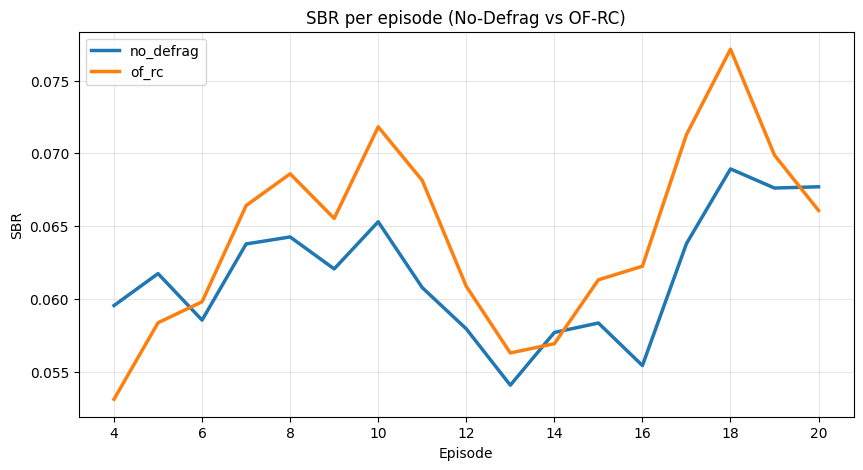

In [95]:
def plot_sbr_curves_smoothed(results, methods=("no_defrag", "of_rc"), window=5, title="SBR per episode"):
    import matplotlib.pyplot as plt
    import numpy as np

    plt.figure(figsize=(10, 5))

    for method in methods:
        key = f"{method}_sbr"
        if key not in results:
            continue

        y = np.asarray(results[key], dtype=float)
        x = np.arange(1, len(y) + 1)

        # Only smoothed curve
        if len(y) >= window:
            y_smooth = np.convolve(y, np.ones(window) / window, mode="valid")
            x_smooth = np.arange(window, len(y) + 1)
            plt.plot(x_smooth, y_smooth, linewidth=2.5, label=method)
        else:
            plt.plot(x, y, linewidth=2.5, label=method)

    plt.xlabel("Episode")
    plt.ylabel("SBR")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

plot_sbr_curves_smoothed(res, methods=("no_defrag", "of_rc"), window=4, title="SBR per episode (No-Defrag vs OF-RC)")

In [14]:
def plot_overhead(results, title="Overhead per episode"):
    episodes = np.arange(len(results["no_defrag_sbr"]))

    # -------------------------
    # Defrag cycles
    # -------------------------
    plt.figure(figsize=(10, 5))

    plt.plot(
        episodes,
        np.zeros_like(episodes),
        marker="o",
        label="No-Defrag cycles",
    )

    if "of_ff_cycles" in results:
        plt.plot(
            episodes,
            results["of_ff_cycles"],
            marker="o",
            label="OF-FF cycles",
        )

    if "of_ff2_cycles" in results:
        plt.plot(
            episodes,
            results["of_ff2_cycles"],
            marker="o",
            label="OF-FF2 cycles",
        )

    plt.xlabel("Episode")
    plt.ylabel("Defrag cycles")
    plt.title(title + " — defrag cycles")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    # -------------------------
    # Reallocations
    # -------------------------
    plt.figure(figsize=(10, 5))

    plt.plot(
        episodes,
        np.zeros_like(episodes),
        marker="o",
        label="No-Defrag reallocations",
    )

    if "of_ff_reallocations" in results:
        plt.plot(
            episodes,
            results["of_ff_reallocations"],
            marker="o",
            label="OF-FF reallocations",
        )

    if "of_ff2_reallocations" in results:
        plt.plot(
            episodes,
            results["of_ff2_reallocations"],
            marker="o",
            label="OF-FF2 reallocations",
        )

    plt.xlabel("Episode")
    plt.ylabel("Actual moved streams")
    plt.title(title + " — reallocations")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()



In [15]:
def plot_reallocations_per_100_arrivals(results, title="Reallocations per 100 arrivals"):
    episodes = np.arange(len(results["no_defrag_sbr"]))

    plt.figure(figsize=(10, 5))

    no_rate = np.zeros_like(episodes, dtype=float)
    plt.plot(
        episodes,
        no_rate,
        marker="o",
        label="No-Defrag realloc / 100 arrivals",
    )

    if "of_ff_reallocations" in results:
        of_rate = 100 * results["of_ff_reallocations"] / np.maximum(results["of_ff_arrivals"], 1)
        plt.plot(
            episodes,
            of_rate,
            marker="o",
            label="OF-FF realloc / 100 arrivals",
        )

    if "of_ff2_reallocations" in results:
        of2_rate = 100 * results["of_ff2_reallocations"] / np.maximum(results["of_ff2_arrivals"], 1)
        plt.plot(
            episodes,
            of2_rate,
            marker="o",
            label="OF-FF2 realloc / 100 arrivals",
        )

    plt.xlabel("Episode")
    plt.ylabel("Reallocations per 100 arrivals")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()



In [16]:
def plot_gain_damage(results, method="of_ff", title=None):
    episodes = np.arange(len(results[f"{method}_gain"]))

    plt.figure(figsize=(10, 5))
    plt.plot(episodes, results[f"{method}_gain"], marker="o", label="Gain")
    plt.plot(episodes, results[f"{method}_damage"], marker="o", label="Damage")
    plt.plot(episodes, results[f"{method}_net_gain"], marker="o", label="Net gain")

    plt.axhline(0, linewidth=1)
    plt.xlabel("Episode")
    plt.ylabel("Number of arrivals")
    plt.title(title or f"{method}: gain / damage / net")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()



In [87]:
def moving_average(x, window=5):
    x = np.asarray(x, dtype=float)

    if window <= 1 or len(x) < window:
        return x

    return np.convolve(x, np.ones(window) / window, mode="valid")